# **Assignment 13 : Tranfer Learning Image Processing CNN Model Training**
- Govardhan

# **Step 1 : Importing Libraries & Modules & Data Loading**

In [4]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

### **Connecting Google Drive to the current notebook**

In [6]:
from google.colab import drive

In [7]:
drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
!find /content/drive/MyDrive -name "*pizza*"

/content/drive/MyDrive/assignment13cnn/train/pizza
/content/drive/MyDrive/assignment13cnn/test/pizza
/content/drive/MyDrive/assignment13cnn/pizza_steak_sushi.zip


In [9]:
# @title
!unzip /content/drive/MyDrive/assignment13cnn/pizza_steak_sushi.zip -d .

Archive:  /content/drive/MyDrive/assignment13cnn/pizza_steak_sushi.zip
   creating: ./test/
   creating: ./train/
   creating: ./test/pizza/
   creating: ./test/steak/
   creating: ./test/sushi/
  inflating: ./test/steak/296375.jpg  
  inflating: ./test/steak/354513.jpg  
  inflating: ./test/steak/690177.jpg  
  inflating: ./test/steak/1882831.jpg  
  inflating: ./test/steak/894825.jpg  
  inflating: ./test/steak/3424937.jpg  
  inflating: ./test/steak/2117351.jpg  
  inflating: ./test/steak/2144308.jpg  
  inflating: ./test/steak/502076.jpg  
  inflating: ./test/steak/100274.jpg  
  inflating: ./test/steak/1285886.jpg  
  inflating: ./test/steak/1302563.jpg  
  inflating: ./test/steak/966174.jpg  
  inflating: ./test/steak/3873283.jpg  
  inflating: ./test/steak/27415.jpg  
  inflating: ./test/steak/1868005.jpg  
  inflating: ./test/steak/1627703.jpg  
  inflating: ./test/steak/673127.jpg  
  inflating: ./test/steak/1016217.jpg  
  inflating: ./test/sushi/479711.jpg  
  inflating: ./t

In [10]:
!dir

drive  sample_data  test  train


In [11]:
!mv test train /content/drive/MyDrive/assignment13cnn/

mv: inter-device move failed: 'test' to '/content/drive/MyDrive/assignment13cnn/test'; unable to remove target: Directory not empty
mv: inter-device move failed: 'train' to '/content/drive/MyDrive/assignment13cnn/train'; unable to remove target: Directory not empty


In [12]:
pwd

'/content'

# **Info Step : UnderStanding Data Info**

In [13]:
train_dir = "/content/drive/MyDrive/assignment13cnn/train"
test_dir = "/content/drive/MyDrive/assignment13cnn/test"

for cls in os.listdir(train_dir):
  cls_path = os.path.join(train_dir, cls)
  if os.path.isdir(cls_path):
    print(f"{cls} : {len(os.listdir(cls_path))} training images")


steak : 75 training images
sushi : 72 training images
pizza : 78 training images


In [14]:
from PIL import Image

train_dir = "/content/drive/MyDrive/assignment13cnn/train"

# Loop through each class folder (pizza, steak, sushi)
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        print(f"\n--- Class: {class_name} ---")

        # Get list of images in this folder
        images = os.listdir(class_path)

        # Let's inspect the first 3 images as an example (or remove [:3] to check all)
        for img_name in images[:3]:
            img_path = os.path.join(class_path, img_name)

            # 1. Get file size on disk (in KB)
            file_size_bytes = os.path.getsize(img_path)
            file_size_kb = file_size_bytes / 1024

            # 2. Open image using PIL to check properties
            with Image.open(img_path) as img:
                width, height = img.size       # Pixel dimensions
                img_format = img.format        # Format (JPEG, PNG, etc.)
                color_mode = img.mode          # Color mode (RGB, RGBA, L, etc.)

                print(f"File: {img_name}")
                print(f"  - Dimensions: {width} x {height} pixels")
                print(f"  - File Size: {file_size_kb:.2f} KB")
                print(f"  - Format: {img_format}")
                print(f"  - Color Mode: {color_mode}")


--- Class: steak ---
File: 2017387.jpg
  - Dimensions: 512 x 512 pixels
  - File Size: 46.99 KB
  - Format: JPEG
  - Color Mode: RGB
File: 1225762.jpg
  - Dimensions: 289 x 512 pixels
  - File Size: 22.11 KB
  - Format: JPEG
  - Color Mode: RGB
File: 256592.jpg
  - Dimensions: 512 x 384 pixels
  - File Size: 75.25 KB
  - Format: JPEG
  - Color Mode: RGB

--- Class: sushi ---
File: 1070104.jpg
  - Dimensions: 512 x 384 pixels
  - File Size: 70.08 KB
  - Format: JPEG
  - Color Mode: RGB
File: 268990.jpg
  - Dimensions: 384 x 512 pixels
  - File Size: 33.55 KB
  - Format: JPEG
  - Color Mode: RGB
File: 1552504.jpg
  - Dimensions: 384 x 512 pixels
  - File Size: 40.47 KB
  - Format: JPEG
  - Color Mode: RGB

--- Class: pizza ---
File: 320570.jpg
  - Dimensions: 382 x 512 pixels
  - File Size: 47.18 KB
  - Format: JPEG
  - Color Mode: RGB
File: 2785084.jpg
  - Dimensions: 512 x 366 pixels
  - File Size: 27.82 KB
  - Format: JPEG
  - Color Mode: RGB
File: 2493954.jpg
  - Dimensions: 512 x 5

# **Step 2 : Image PreProcessing and Data Augementation**

What we do in this Step:


*   Neural networks cannot process raw images of varying sizes out-of-the-box. We use transforms to resize images uniformly, convert them into numbers (tensors), normalize pixel values using ImageNet statistics, and apply data augmentation (flips, rotations, color jitter) to make our model robust against real-world variations.
*   Data augmentation is a powerful machine learning technique used to artificially expand a training dataset. Instead of collecting completely new data, it creates slightly modified versions of the data you already have.

*   The primary goal is to prevent overfitting and help the model generalize better so that it performs well on real-world, unseen data.





In [15]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Training transforms with Data Augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),               # Standard CNN input size
    transforms.RandomHorizontalFlip(),         # Flip left-to-right randomly
    transforms.RandomRotation(15),             # Rotate slightly (up to 15°)
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Handle lighting differences
    transforms.ToTensor(),                     # Convert to PyTorch Tensor [0, 1 scale]
    transforms.Normalize(                      # Center pixels around ImageNet mean/std
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Testing transforms (NO augmentation, clean evaluation)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets using ImageFolder
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(root=test_dir, transform=test_transform)

# Create DataLoaders for mini-batch processing
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

class_names = train_dataset.classes
print(f"\nClasses detected: {class_names}")


Classes detected: ['pizza', 'steak', 'sushi']


In [16]:
train_dataset

Dataset ImageFolder
    Number of datapoints: 225
    Root location: /content/drive/MyDrive/assignment13cnn/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

# **Model 1 : ResNet50**

**ResNet50 (Residual Networks)**:Mechanism: Relies on additive skip connections (or shortcut connections) that bypass one or more layers. Mathematically, a layer learns a residual mapping $F(x)$, and the output is defined as $F(x) + x$.

**Flow of Information**: This addition allows gradients to flow directly backward through the network without vanishing, making deep networks stable to train. It focuses the network on learning what incremental changes need to be made to the feature maps.

# **Step 3 : Implement Tranfer Learning and train the model**

**What we are doing:**
Instead of training a model from scratch, we load a pre-trained ResNet50 architecture that already knows how to detect shapes, edges, and textures from millions of ImageNet images.

We freeze its feature-extraction layers so we don't destroy its prior knowledge.

We replace the final classification head to output 3 classes instead of 1,000.

We run a training loop using Gradient Descent to fine-tune the model on our food images.

In [17]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet50, ResNet50_Weights

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Load pre-trained ResNet50
model = resnet50(weights=ResNet50_Weights.DEFAULT)

# Unfreeze the last block of ResNet50 (layer4) for fine-tuning
for name, param in model.named_parameters():
    if "layer4" in name or "fc" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False



# 3. Replace classification head for 3 classes
num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, len(class_names))
)

model = model.to(device)

# Loss function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001)
# Use a very small learning rate for fine-tuning so we don't break pre-trained weights
print("ResNet50 layer4 and classification head are now unfrozen for fine-tuning!")
# 4. Training Loop
num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc*100:.2f}%")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 182MB/s]


ResNet50 layer4 and classification head are now unfrozen for fine-tuning!
Epoch [1/5] | Loss: 1.0858 | Accuracy: 44.00%
Epoch [2/5] | Loss: 0.9981 | Accuracy: 84.89%
Epoch [3/5] | Loss: 0.8579 | Accuracy: 93.78%
Epoch [4/5] | Loss: 0.6469 | Accuracy: 96.89%
Epoch [5/5] | Loss: 0.4013 | Accuracy: 96.44%


# **Step 4: Evaluation and Performance Metrics**
**What we are doing:**
Once trained, we test our model's generalization performance on unseen data (test_loader). We compute professional evaluation metrics - Accuracy, Precision, Recall, F1-Score, and a Confusion Matrix - to understand exactly where the model succeeds or gets confused.

In [32]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Print detailed evaluation report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:
              precision    recall  f1-score   support

       pizza       1.00      0.96      0.98        25
       steak       0.90      0.95      0.92        19
       sushi       0.97      0.97      0.97        31

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



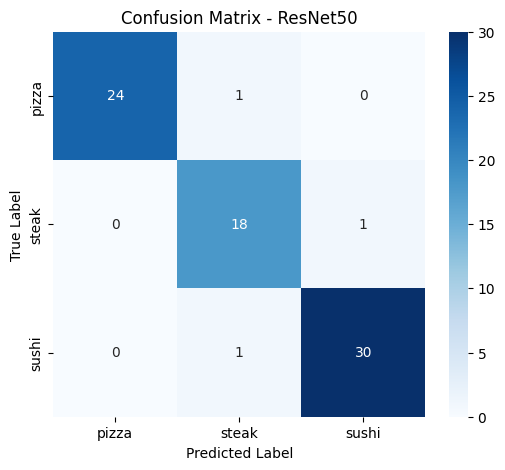

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm_resnet = confusion_matrix(all_labels, all_preds)

# Plot using Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - ResNet50')
plt.show()

# **Model 2 : DenseNet121**

**DenseNet121 (Densely Connected Convolutional Networks)**:Mechanism: Employs feature concatenation instead of addition. Every layer receives the feature maps of all preceding layers as direct inputs ($x_0, x_1, x_2, \dots, x_{l-1}$).


**Flow of Information**: This maximizes feature reuse and heavily reduces the parameter count, but causes channel dimensions to grow progressively wider within dense blocks. While highly efficient for parameter usage, the dense web of connections can sometimes make selective layer fine-tuning more intricate on smaller datasets.

# **Step 1: Train/Fine-Tune DenseNet121**

In [35]:
from torchvision.models import densenet121, DenseNet121_Weights

# 1. Load DenseNet121
densenet_model = densenet121(weights=DenseNet121_Weights.DEFAULT)

# Unfreeze the last dense block and transition layer of DenseNet121
for name, param in densenet_model.named_parameters():
    if "denseblock4" in name or "norm5" in name or "classifier" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

# 3. Replace classification head (DenseNet uses 'classifier' instead of 'fc')
num_features_dense = densenet_model.classifier.in_features
densenet_model.classifier = nn.Sequential(
    nn.Linear(num_features_dense, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, len(class_names))
)

densenet_model = densenet_model.to(device)
print("DenseNet121 loaded and customized successfully!")

DenseNet121 loaded and customized successfully!


In [39]:
# 1. Define loss function and optimizer for DenseNet121
criterion = nn.CrossEntropyLoss()
# Use a small learning rate for fine-tuning
optimizer = optim.Adam(filter(lambda p: p.requires_grad, densenet_model.parameters()), lr=0.0001)

# 2. Training Loop
num_epochs = 5
print("Starting DenseNet121 Training...")

for epoch in range(num_epochs):
    densenet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = densenet_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc*100:.2f}%")

Starting DenseNet121 Training...
Epoch [1/5] | Loss: 0.4732 | Accuracy: 85.78%
Epoch [2/5] | Loss: 0.3270 | Accuracy: 93.33%
Epoch [3/5] | Loss: 0.2438 | Accuracy: 97.33%
Epoch [4/5] | Loss: 0.2091 | Accuracy: 99.11%
Epoch [5/5] | Loss: 0.1573 | Accuracy: 98.67%


# **Step 2: Evaluate DenseNet121 and Print the Report**
Once training finishes, evaluate it on your test set and generate its classification report to see how it compares against your 92% ResNet50 model:

In [23]:
from sklearn.metrics import classification_report

densenet_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = densenet_model(images)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\nDenseNet121 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))


DenseNet121 Classification Report:
              precision    recall  f1-score   support

       pizza       1.00      0.84      0.91        25
       steak       0.76      1.00      0.86        19
       sushi       0.97      0.90      0.93        31

    accuracy                           0.91        75
   macro avg       0.91      0.91      0.90        75
weighted avg       0.92      0.91      0.91        75



# **Step 3: Generate the Confusion Matrix Plot**
To fulfill the visual requirements for your Jupyter Notebook and Project Report, run this code to plot the confusion matrix for your final model:

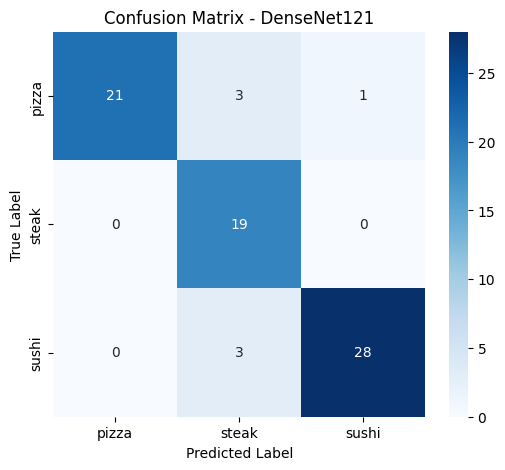

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm_dense = confusion_matrix(all_labels, all_preds)

# Plot heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dense, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - DenseNet121')
plt.show()

## **Notes:**

Precision (The Quality Metric)What it measures: Out of all the images the model predicted as a specific class, how many were actually correct?   Why it matters: High precision means low false positives. For example, if your model predicts "Steak," precision tells you how often it is actually steak instead of misclassified pizza.
- 90% it was correct.


Recall / Sensitivity (The Quantity Metric)What it matters: Out of all the actual images of a specific class in the test set, how many did the model successfully find?Why it matters: High recall means low false negatives. If there are 20 true sushi images, recall tells you how many of those 20 the model successfully caught.

- 75% it model successfully caught.


# **Final Step : Pandas metrics & Confusion Matrix Between ResNet & DenseNet**

In [37]:
import pandas as pd

# Define your results data
comparison_data = {
    'Model Architecture': ['DenseNet121 (Fine-Tuned)', 'ResNet50 (Fine-Tuned)'],
    'Overall Accuracy': ['91.0%', '96.0%'],
    'Pizza F1-Score': [0.91, 0.98],
    'Steak F1-Score': [0.86, 0.92],
    'Sushi F1-Score': [0.93, 0.97],
    'Macro Average F1': [0.90, 0.96]
}

# Create and display dataframe
df_comparison = pd.DataFrame(comparison_data)
display(df_comparison)

,Model Architecture,Overall Accuracy,Pizza F1-Score,Steak F1-Score,Sushi F1-Score,Macro Average F1
0,DenseNet121 (Fine-Tuned),91.0%,0.91,0.86,0.93,0.90
1,ResNet50 (Fine-Tuned),96.0%,0.98,0.92,0.97,0.96


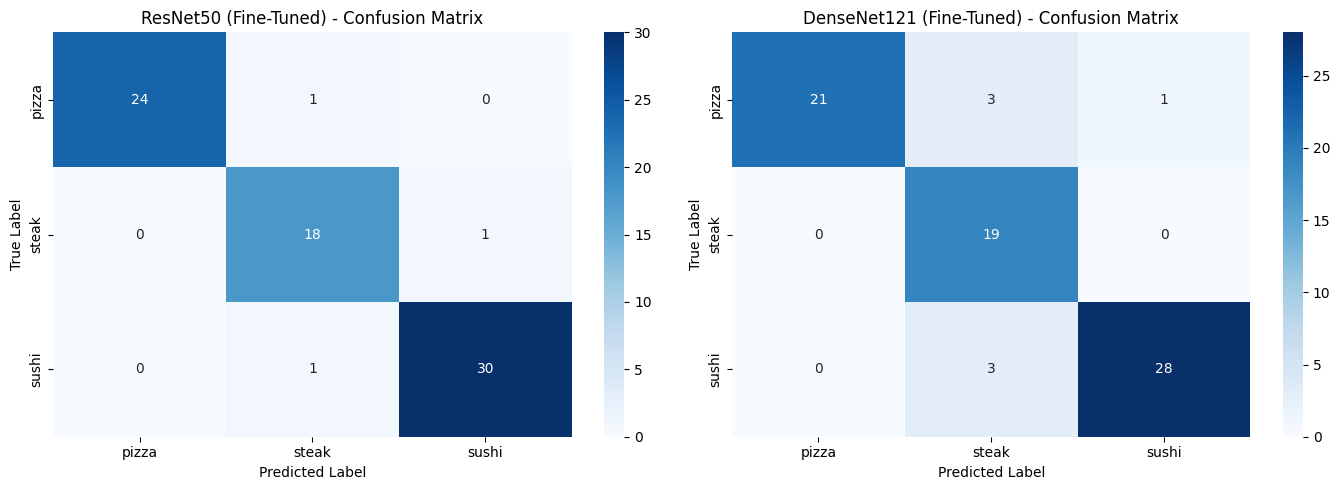

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming you already saved your predictions and true labels for both models:
# cm_resnet = confusion_matrix(true_labels, resnet_preds)
# cm_dense = confusion_matrix(true_labels, dense_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ResNet50 Confusion Matrix
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title('ResNet50 (Fine-Tuned) - Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. DenseNet121 Confusion Matrix
sns.heatmap(cm_dense, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('DenseNet121 (Fine-Tuned) - Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()